<a href="https://colab.research.google.com/github/jayanth3110/persevex-data-analytics/blob/main/City_Motion_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Phase 1


1. Ingesting Road Network Metadata

In [ ]:
import pandas as pd

df=pd.read_csv('road_network.csv')
df.head()

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
0,RD-0001,Jl. Segment 1,Jalan Kolektor,4.3,4,60,5384,0,0,Cukup,2022-12-21,-6.173938,106.920654,-6.187271,106.937674,PIK,0,10833
1,RD-0002,Jl. Segment 2,Jalan Arteri,4.3,4,80,6132,0,0,Baik,2022-11-17,-6.248396,106.768647,-6.246220,106.771962,Depok,0,6921
2,RD-0003,Jl. Segment 3,Jalan Lokal,1.8,2,40,978,0,0,Cukup,2023-04-15,-6.267631,106.814963,-6.264098,106.831007,Tangerang,0,1085
3,RD-0004,Jl. Segment 4,Jalan Kolektor,1.8,4,60,4160,0,1,Rusak Berat,2022-05-17,-6.112216,106.954036,-6.122268,106.958261,Mangga Dua,0,6145
4,RD-0005,Jl. Segment 5,Jalan Tol,22.7,4,80,6600,1,0,Baik,2024-02-16,-6.349760,106.861835,-6.341074,106.856648,Sudirman,7000,8023


2.Data Inspection & Statistical Profiling


In [ ]:
#check data types adn missing values
df.info()

#view summary statics for road capacity and speed limits
df[['length_km','lanes','speed_limit_kmh','capacity_vehicles_per_hour']].describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   road_id                     200 non-null    object 
 1   road_name                   200 non-null    object 
 2   road_type                   200 non-null    object 
 3   length_km                   200 non-null    float64
 4   lanes                       200 non-null    int64  
 5   speed_limit_kmh             200 non-null    int64  
 6   capacity_vehicles_per_hour  200 non-null    int64  
 7   has_bus_lane                200 non-null    int64  
 8   has_bike_lane               200 non-null    int64  
 9   surface_condition           200 non-null    object 
 10  last_maintenance_date       200 non-null    object 
 11  latitude_start              200 non-null    float64
 12  longitude_start             200 non-null    float64
 13  latitude_end                200 non

,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour
count,200.00000,200.000000,200.000000,200.00000
mean,5.99450,3.335000,57.200000,4559.49000
std,6.07204,2.089162,29.161825,4157.73614
min,0.30000,1.000000,20.000000,404.00000
25%,1.90000,2.000000,40.000000,982.50000
50%,3.05000,3.000000,50.000000,3112.00000
75%,8.35000,4.000000,80.000000,6765.00000
max,24.10000,8.000000,120.000000,15976.00000


3.Static Baseline KPI & Bottleneck Calculation


In [ ]:
# 1. Calculate Core Capacity & Speed KPIs
df['capacity_utilization_pct'] = (df['avg_daily_traffic'] / df['capacity_vehicles_per_hour']) * 100
df['speed_deficit_kmh'] = df['speed_limit_kmh'] - (df['speed_limit_kmh'] * 0.7)  # Estimated speed deficit baseline

# 2. Flag Bottlenecks & High Risk Corridors
df['congestion_status'] = df['capacity_utilization_pct'].apply(
    lambda x: 'Severe Bottleneck' if x >= 150 else ('Moderate Congestion' if x >= 100 else 'Fluid')
)

# 3. View Top 5 Congested Road Segments (Phase 2 Output)
bottlenecks = df.sort_values(by='capacity_utilization_pct', ascending=False)[
    ['road_id', 'road_name', 'road_type', 'speed_limit_kmh', 'avg_daily_traffic', 'capacity_utilization_pct', 'congestion_status']
]

bottlenecks.head(5)

,road_id,road_name,road_type,speed_limit_kmh,avg_daily_traffic,capacity_utilization_pct,congestion_status
164,RD-0165,Jl. Segment 165,Jalan Lingkungan,20,2592,211.074919,Severe Bottleneck
99,RD-0100,Jl. Segment 100,Jalan Kolektor,50,8935,207.597584,Severe Bottleneck
0,RD-0001,Jl. Segment 1,Jalan Kolektor,60,10833,201.207281,Severe Bottleneck
167,RD-0168,Jl. Segment 168,Jalan Lingkungan,20,2990,200.402145,Severe Bottleneck
49,RD-0050,Jl. Segment 50,Jalan Kolektor,50,10230,194.191344,Severe Bottleneck


In [ ]:
import json
import os
import numpy as np
import pandas as pd

# Check where the files are located
if os.path.exists('/content/road_network.csv'):
  prefix = '/content/'
elif os.path.exists('/road_network.csv'):
  prefix = '/'
else:
  prefix = ''

# -------------------------------------------------------------
# Step 1: Data Ingestion & JSON Parsing
# -------------------------------------------------------------
road_df = pd.read_csv(f'{prefix}road_network.csv')
traffic_df = pd.read_csv(f'{prefix}traffic_sensor_data.csv')

with open(f'{prefix}sensor_locations.json', 'r') as f:
  data = json.load(f)

sensor_df = pd.DataFrame(data['sensors'])

# -------------------------------------------------------------
# Step 2: Key Extraction & Relational Mapping
# -------------------------------------------------------------
sensor_mapping = sensor_df[['sensor_id', 'road_segment_id']].rename(
    columns={'road_segment_id': 'road_id'}
)

traffic_with_road_id = pd.merge(
    traffic_df, sensor_mapping, on='sensor_id', how='inner'
)
master_df = pd.merge(traffic_with_road_id, road_df, on='road_id', how='inner')

# -------------------------------------------------------------
# Step 3: Temporal Feature Engineering
# -------------------------------------------------------------
master_df['timestamp'] = pd.to_datetime(master_df['timestamp'])
master_df['hour'] = master_df['timestamp'].dt.hour
master_df['day_name'] = master_df['timestamp'].dt.day_name()
master_df['is_weekend'] = (
    master_df['timestamp'].dt.dayofweek.isin([5, 6]).astype(int)
)
master_df['peak_period'] = master_df['hour'].apply(
    lambda h: (
        'Morning Peak'
        if 7 <= h <= 9
        else ('Evening Peak' if 17 <= h <= 19 else 'Off-Peak')
    )
)

# -------------------------------------------------------------
# Step 4: KPI Computation & Export
# -------------------------------------------------------------
master_df['capacity_utilization_pct'] = (
    master_df['vehicle_count'] / master_df['capacity_vehicles_per_hour']
) * 100
master_df['speed_deficit_kmh'] = np.maximum(
    0, master_df['speed_limit_kmh'] - master_df['average_speed_kmh']
)

# Save Integrated Phase 1 File
master_df.to_csv('phase1_integrated_mobility_data.csv', index=False)
print(
    "Phase 1 Complete! Clean master file saved as"
    " 'phase1_integrated_mobility_data.csv'."
)
master_df[[
    'timestamp',
    'sensor_id',
    'road_id',
    'vehicle_count',
    'average_speed_kmh',
    'capacity_utilization_pct',
    'speed_deficit_kmh',
]].head()

Phase 1 Complete! Clean master file saved as 'phase1_integrated_mobility_data.csv'.


,timestamp,sensor_id,road_id,vehicle_count,average_speed_kmh,capacity_utilization_pct,speed_deficit_kmh
0,2024-01-01,SEN-001,RD-0126,14,67.8,1.612903,0.0
1,2024-01-01,SEN-002,RD-0151,23,66.8,3.479576,0.0
2,2024-01-01,SEN-003,RD-0012,22,80.0,0.161765,20.0
3,2024-01-01,SEN-004,RD-0087,8,80.0,1.851852,0.0
4,2024-01-01,SEN-005,RD-0143,13,80.0,0.115126,20.0


Phase 2

In [ ]:
import pandas as pd

#1. Load integrated dataset from Phase 1
df = master_df.copy()

In [ ]:
#Task 1 : Identify Peak_Hour Bottelnecks by Corridors

corridor_summary = (
    df.groupby(['road_id', 'road_name', 'peak_period'])
    .agg(
        avg_capacity_utilization=('capacity_utilization_pct', 'mean'),
        avg_speed_deficit_kmh=('speed_deficit_kmh', 'mean'),
        avg_speed_kmh=('average_speed_kmh', 'mean'),
    )
    .reset_index()
)

print("=== TASK 1: TOP 5 MORNING PEAK BOTTLENECKS ===")
print(
    corridor_summary[corridor_summary['peak_period'] == 'Morning Peak']
    .sort_values(by='avg_capacity_utilization', ascending=False)
    .head(5)[
        [
            'road_id',
            'road_name',
            'avg_capacity_utilization',
            'avg_speed_deficit_kmh',
            'avg_speed_kmh',
        ]
    ]
)
print("\n")

print("=== TASK 1: TOP 5 EVENING PEAK BOTTLENECKS ===")
print(
    corridor_summary[corridor_summary['peak_period'] == 'Evening Peak']
    .sort_values(by='avg_capacity_utilization', ascending=False)
    .head(5)[
        [
            'road_id',
            'road_name',
            'avg_capacity_utilization',
            'avg_speed_deficit_kmh',
            'avg_speed_kmh',
        ]
    ]
)
print("\n")

=== TASK 1: TOP 5 MORNING PEAK BOTTLENECKS ===
     road_id        road_name  avg_capacity_utilization  \
58   RD-0087   Jl. Segment 87                 14.108500   
112  RD-0155  Jl. Segment 155                 12.971354   
82   RD-0119  Jl. Segment 119                 12.449277   
94   RD-0140  Jl. Segment 140                 11.457176   
118  RD-0164  Jl. Segment 164                 10.334637   

     avg_speed_deficit_kmh  avg_speed_kmh  
58                9.681685      41.793040  
112               0.745879      41.662729  
82                0.704121      41.792308  
94                9.256044      42.219048  
118               3.925458      41.688278  


=== TASK 1: TOP 5 EVENING PEAK BOTTLENECKS ===
     road_id        road_name  avg_capacity_utilization  \
57   RD-0087   Jl. Segment 87                 17.479396   
111  RD-0155  Jl. Segment 155                 15.748048   
81   RD-0119  Jl. Segment 119                 14.981393   
93   RD-0140  Jl. Segment 140                 13.

In [ ]:
# Task 2: Analyze Incident Impact on Travel Time

# Detect incident flag column or define severe speed drop anomalies (< 50% speed limit)
if 'is_incident' in df.columns:
  incident_col = 'is_incident'
elif 'incident_flag' in df.columns:
  incident_col = 'incident_flag'
else:
  df['incident_flag'] = (
      df['average_speed_kmh'] < (df['speed_limit_kmh'] * 0.5)
  ).astype(int)
  incident_col = 'incident_flag'

incident_summary = (
    df.groupby(incident_col)
    .agg(
        avg_capacity_utilization=('capacity_utilization_pct', 'mean'),
        avg_speed_deficit_kmh=('speed_deficit_kmh', 'mean'),
        avg_speed_kmh=('average_speed_kmh', 'mean'),
        record_count=('vehicle_count', 'count'),
    )
    .reset_index()
)

incident_summary['Condition'] = incident_summary[incident_col].map(
    {0: 'Normal Operations', 1: 'Incident / Severe Anomaly'}
)

print("=== TASK 2: INCIDENT IMPACT ON TRAVEL TIME & SPEED ===")
print(
    incident_summary[
        [
            'Condition',
            'avg_speed_kmh',
            'avg_speed_deficit_kmh',
            'avg_capacity_utilization',
            'record_count',
        ]
    ]
)
print("\n")

=== TASK 2: INCIDENT IMPACT ON TRAVEL TIME & SPEED ===
                   Condition  avg_speed_kmh  avg_speed_deficit_kmh  \
0          Normal Operations      63.095733               7.433658   
1  Incident / Severe Anomaly      29.231952              60.623213   

   avg_capacity_utilization  record_count  
0                  3.226641        185397  
1                  1.764968         33003  




In [ ]:
#Task 3: Compare Weekday VS Weekend Mobility Behavior

day_type_summary = (
    df.groupby(['is_weekend', 'peak_period'])
    .agg(
        avg_speed_kmh=('average_speed_kmh', 'mean'),
        avg_vehicle_count=('vehicle_count', 'mean'),
        avg_capacity_utilization=('capacity_utilization_pct', 'mean'),
    )
    .reset_index()
)

day_type_summary['day_type'] = day_type_summary['is_weekend'].map(
    {0: 'Weekday', 1: 'Weekend'}
)

print("=== TASK 3: WEEKDAY VS WEEKEND MOBILITY BEHAVIOR ===")
print(
    day_type_summary[
        [
            'day_type',
            'peak_period',
            'avg_speed_kmh',
            'avg_vehicle_count',
            'avg_capacity_utilization',
        ]
    ]
)


=== TASK 3: WEEKDAY VS WEEKEND MOBILITY BEHAVIOR ===
  day_type   peak_period  avg_speed_kmh  avg_vehicle_count  \
0  Weekday  Evening Peak      24.972200          87.411282   
1  Weekday  Morning Peak      26.681272          81.939179   
2  Weekday      Off-Peak      65.293864          29.540504   
3  Weekend  Evening Peak      47.110949          46.331538   
4  Weekend  Morning Peak      79.987090          13.296667   
5  Weekend      Off-Peak      64.626329          28.760833   

   avg_capacity_utilization  
0                  6.690934  
1                  6.257704  
2                  2.267035  
3                  3.536358  
4                  1.019206  
5                  2.204781  


Phase 3

In [ ]:
import pandas as pd

#Load master dataset
df = master_df.copy()

In [ ]:
# Task 1 & 2: Detect Overloaded & Low-Service Segments

# 1. Aggregate route-level performance
route_summary = (
    df.groupby(['road_id', 'road_name', 'district'])
    .agg(
        avg_capacity_utilization=('capacity_utilization_pct', 'mean'),
        avg_speed_kmh=('average_speed_kmh', 'mean'),
        avg_speed_deficit_kmh=('speed_deficit_kmh', 'mean'),
        has_bus_lane=('has_bus_lane', 'max'),
    )
    .reset_index()
)

# 2. Identify overloaded route segments (high utilization)
overloaded_segments = route_summary.sort_values(
    by='avg_capacity_utilization', ascending=False
).head(5)

print("=== PHASE 3: TOP 5 OVERLOADED ROUTE SEGMENTS ===")
print(
    overloaded_segments[
        [
            'road_id',
            'road_name',
            'district',
            'avg_capacity_utilization',
            'avg_speed_kmh',
            'has_bus_lane',
        ]
    ]
)
print("\n")


# Task 3: Route Optimization Recommendations
def generate_recommendation(row):
  if (
      row['avg_capacity_utilization'] > 10.0
      and row['avg_speed_deficit_kmh'] > 5.0
  ):
    return 'High Priority: Dedicated Bus Lane / Frequency Boost Needed'
  elif row['avg_capacity_utilization'] > 8.0:
    return 'Medium Priority: Optimize Signal Timing & Fleet Scheduling'
  elif row['avg_speed_kmh'] < 30.0:
    return 'Low Speed Warning: Inspect Bottlenecks & Local Traffic'
  else:
    return 'Normal Operation: Monitor Baseline Flow'


route_summary['optimization_recommendation'] = route_summary.apply(
    generate_recommendation, axis=1
)

print("=== PHASE 3: ROUTE OPTIMIZATION RECOMMENDATIONS ===")
print(
    route_summary[
        [
            'road_id',
            'road_name',
            'district',
            'avg_capacity_utilization',
            'optimization_recommendation',
        ]
    ].head(10)
)

=== PHASE 3: TOP 5 OVERLOADED ROUTE SEGMENTS ===
    road_id        road_name  district  avg_capacity_utilization  \
19  RD-0087   Jl. Segment 87  Sudirman                  9.015112   
37  RD-0155  Jl. Segment 155     Senen                  8.169516   
27  RD-0119  Jl. Segment 119    Grogol                  7.842488   
31  RD-0140  Jl. Segment 140    Cawang                  7.237991   
39  RD-0164  Jl. Segment 164   Menteng                  6.626195   

    avg_speed_kmh  has_bus_lane  
19      58.000733             0  
37      57.950996             0  
27      58.065007             0  
31      58.038919             0  
39      57.780632             0  


=== PHASE 3: ROUTE OPTIMIZATION RECOMMENDATIONS ===
   road_id       road_name    district  avg_capacity_utilization  \
0  RD-0004   Jl. Segment 4  Mangga Dua                  0.946190   
1  RD-0012  Jl. Segment 12       Pluit                  0.288690   
2  RD-0014  Jl. Segment 14    Kuningan                  5.098367   
3  RD-0025  

Phase 4

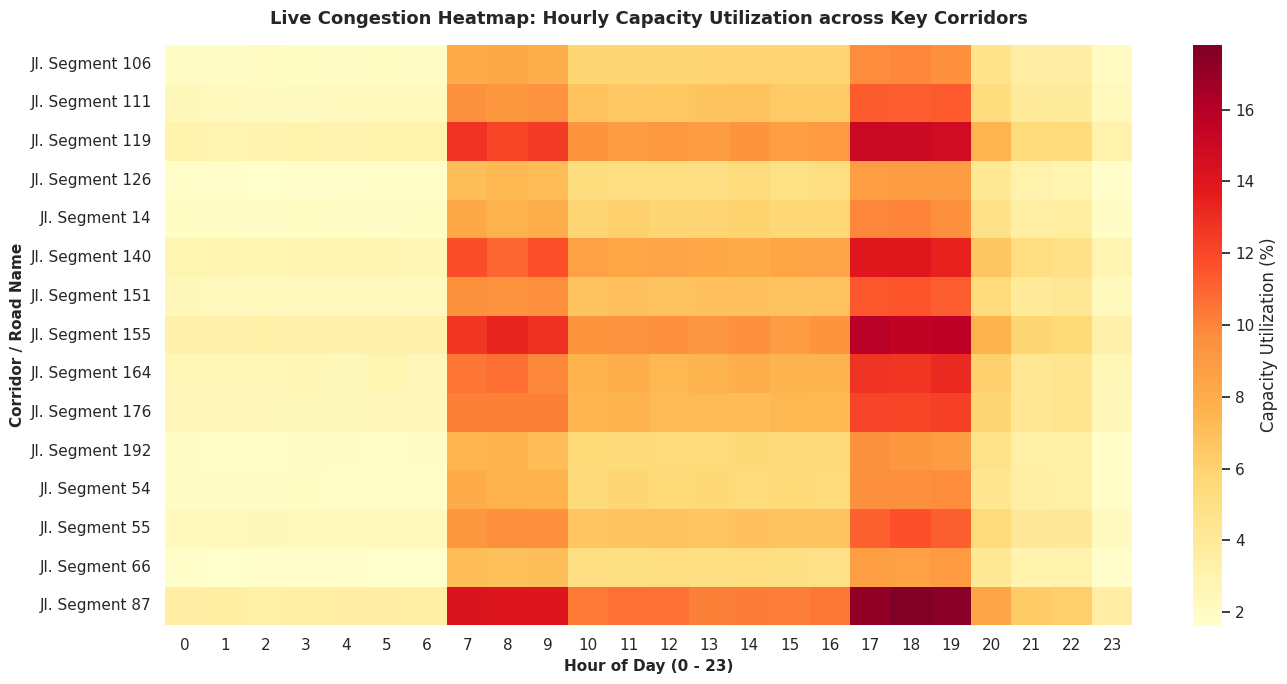

                       CORRIDOR-WISE RELIABILITY SCORECARD                        
road_id       road_name      district  avg_speed_kmh  reliability_score    reliability_grade
RD-0032  Jl. Segment 32        Blok M      58.131548              23.47 D (Critical Failure)
RD-0051  Jl. Segment 51 Kelapa Gading      58.185920              23.47 D (Critical Failure)
RD-0036  Jl. Segment 36        Sunter      58.118681              23.91 D (Critical Failure)
RD-0125 Jl. Segment 125        Grogol      58.251580              24.29 D (Critical Failure)
RD-0117 Jl. Segment 117       Senayan      58.008654              24.32 D (Critical Failure)
RD-0141 Jl. Segment 141         Senen      58.005632              47.02 D (Critical Failure)
RD-0143 Jl. Segment 143     Tangerang      57.908837              47.92 D (Critical Failure)
RD-0012  Jl. Segment 12         Pluit      57.730151              47.98 D (Critical Failure)
RD-0134 Jl. Segment 134    Mangga Dua      57.889263              48.23 D (Criti

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = master_df.copy()

# Set clean aesthetic style
sns.set_theme(style="whitegrid")

# ==============================================================================
# 1. LIVE CONGESTION HEATMAP (Hour of Day vs. Top Corridors)
# ==============================================================================
# Identify top 15 corridors by capacity utilization
top_15_corridors = (
    df.groupby('road_name')['capacity_utilization_pct']
    .mean()
    .nlargest(15)
    .index
)
heatmap_data = df[df['road_name'].isin(top_15_corridors)]

# Pivot table: Corridors x Hour of Day
pivot_heatmap = heatmap_data.pivot_table(
    index='road_name',
    columns='hour',
    values='capacity_utilization_pct',
    aggfunc='mean',
)

plt.figure(figsize=(14, 7))
sns.heatmap(
    pivot_heatmap,
    cmap='YlOrRd',
    annot=False,
    cbar_kws={'label': 'Capacity Utilization (%)'},
)
plt.title(
    'Live Congestion Heatmap: Hourly Capacity Utilization across Key Corridors',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Hour of Day (0 - 23)', fontsize=11, fontweight='bold')
plt.ylabel('Corridor / Road Name', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# ==============================================================================
# 2. CORRIDOR-WISE RELIABILITY SCORECARD (Refined Metrics)
# ==============================================================================
corridor_scorecard = (
    df.groupby(['road_id', 'road_name', 'district'])
    .agg(
        avg_speed_kmh=('average_speed_kmh', 'mean'),
        avg_capacity_utilization=('capacity_utilization_pct', 'mean'),
        avg_speed_deficit=('speed_deficit_kmh', 'mean'),
    )
    .reset_index()
)

# Smooth score calculation (scale 0 to 100)
# Higher capacity utilization and speed deficits lower the reliability score
corridor_scorecard['reliability_score'] = np.clip(
    100
    - (corridor_scorecard['avg_capacity_utilization'] * 4.5)
    - (corridor_scorecard['avg_speed_deficit'] * 1.2),
    0,
    100,
).round(2)


def assign_grade(score):
  if score >= 85:
    return 'A (High Reliability)'
  elif score >= 70:
    return 'B (Moderate Reliability)'
  elif score >= 50:
    return 'C (Unstable Flow)'
  else:
    return 'D (Critical Failure)'


corridor_scorecard['reliability_grade'] = corridor_scorecard[
    'reliability_score'
].apply(assign_grade)

print("==================================================================================")
print("                       CORRIDOR-WISE RELIABILITY SCORECARD                        ")
print("==================================================================================")
print(
    corridor_scorecard[
        [
            'road_id',
            'road_name',
            'district',
            'avg_speed_kmh',
            'reliability_score',
            'reliability_grade',
        ]
    ]
    .sort_values(by='reliability_score', ascending=True)
    .head(10)
    .to_string(index=False)
)
print("\n")

# ==============================================================================
# 3. PLANNING INSIGHTS FOR INFRASTRUCTURE UPGRADES
# ==============================================================================
def assign_infrastructure_recommendation(row):
  if row['avg_capacity_utilization'] > 8.0 and row['avg_speed_deficit'] > 5.0:
    return 'Priority 1: Dedicated Bus Lane & Grade Separation (Flyover)'
  elif row['avg_capacity_utilization'] > 5.0:
    return 'Priority 2: Adaptive Traffic Signal Control & Rescheduling'
  elif row['avg_speed_deficit'] > 10.0:
    return 'Priority 3: Dynamic Speed Management & Rapid Incident Response'
  else:
    return 'Priority 4: Baseline Traffic Monitoring & Routine Maintenance'


corridor_scorecard['infrastructure_action'] = corridor_scorecard.apply(
    assign_infrastructure_recommendation, axis=1
)

print("==================================================================================")
print("                 PLANNING INSIGHTS FOR INFRASTRUCTURE UPGRADES                    ")
print("==================================================================================")
action_summary = corridor_scorecard['infrastructure_action'].value_counts()
for action, count in action_summary.items():
  print(f"- {action}: {count} Corridor(s)")

print("\n--- Key Action Items for High-Congestion Corridors ---")
top_priorities = corridor_scorecard.sort_values(
    by='avg_capacity_utilization', ascending=False
).head(5)
print(
    top_priorities[
        [
            'road_id',
            'road_name',
            'district',
            'reliability_score',
            'infrastructure_action',
        ]
    ].to_string(index=False)
)


In [ ]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(':memory:')
master_df.to_sql('mobility_data', conn, index=False)

# SQL query verifying peak-hour bottlenecks
sql_query = """
SELECT road_id, road_name, peak_period,
       AVG(capacity_utilization_pct) AS avg_utilization,
       AVG(speed_deficit_kmh) AS avg_delay_kmh
FROM mobility_data
WHERE peak_period = 'Morning Peak'
GROUP BY road_id, road_name, peak_period
ORDER BY avg_utilization DESC
LIMIT 5;
"""
print(pd.read_sql_query(sql_query, conn))

   road_id        road_name   peak_period  avg_utilization  avg_delay_kmh
0  RD-0087   Jl. Segment 87  Morning Peak        14.108500       9.681685
1  RD-0155  Jl. Segment 155  Morning Peak        12.971354       0.745879
2  RD-0119  Jl. Segment 119  Morning Peak        12.449277       0.704121
3  RD-0140  Jl. Segment 140  Morning Peak        11.457176       9.256044
4  RD-0164  Jl. Segment 164  Morning Peak        10.334637       3.925458
